# 06 — Training Report

Laporan hasil training keempat kandidat (**Prophet, LSTM, GRU, TFT**) dari tabel
`gds_datasource.model_comparation_metric_hourly` (sumber yang sama dengan dashboard
Looker Studio). Satu baris = `model × station × horizon` dengan metrik `RMSE`, `MAE`,
`sMAPE`, dan `NSE`.

Cara baca cepat:
- **NSE** makin tinggi makin baik (1 = sempurna, 0 = sama buruknya dengan menebak rata-rata, < 0 = lebih buruk dari rata-rata).
- **RMSE / MAE / sMAPE** makin rendah makin baik.
- `horizon` dalam jam ke depan (1, 3, 12).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

PROJECT_ID = "thesis-506605"
QUERY = "SELECT * FROM `thesis-506605.gds_datasource.model_comparation_metric_hourly` LIMIT 1000"

try:  # Colab
    from google.colab import auth
    auth.authenticate_user()
except ImportError:  # lokal: pakai Application Default Credentials (gcloud auth application-default login)
    pass

from google.cloud import bigquery
df = bigquery.Client(project=PROJECT_ID).query(QUERY).to_dataframe()

MODELS   = ["prophet", "lstm", "gru", "tft"]
HORIZONS = sorted(int(h) for h in df["horizon"].unique())
STATIONS = sorted(df["station"].unique())
METRICS  = ["NSE", "RMSE", "MAE", "sMAPE"]
HIGHER_IS_BETTER = {"NSE": True, "RMSE": False, "MAE": False, "sMAPE": False}

print(f"{len(df)} baris | {df['model'].nunique()} model | {df['station'].nunique()} stasiun | horizon {HORIZONS}")
assert len(df) == len(MODELS) * len(STATIONS) * len(HORIZONS), "ada kombinasi model/stasiun/horizon yang hilang atau dobel"
df.head()

D:\Thesis\flood_forecasting_pipeline\.venv\Lib\site-packages\google\auth\_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


D:\Thesis\flood_forecasting_pipeline\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2130: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


96 baris | 4 model | 8 stasiun | horizon [1, 3, 12]


,model,station,horizon,RMSE,MAE,sMAPE,NSE
0,prophet,Bendung Katulampa,1,0.049383,0.030562,29.638474,0.482839
1,lstm,Bendung Katulampa,1,0.020515,0.009534,9.517538,0.910358
2,gru,Bendung Katulampa,1,0.020456,0.009363,8.531754,0.910874
3,tft,Bendung Katulampa,1,0.022090,0.011337,11.823899,0.896063
4,prophet,Bendung Katulampa,3,0.050563,0.030953,30.019935,0.457953


In [2]:
# Satu warna per model, urutan tetap di semua plot (slot kategorikal 1-4, juga dibedakan lewat marker).
COLOR  = {"prophet": "#2a78d6", "lstm": "#eb6834", "gru": "#1baf7a", "tft": "#eda100"}
MARKER = {"prophet": "o", "lstm": "s", "gru": "^", "tft": "D"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
NSE_RAMP = LinearSegmentedColormap.from_list("nse", ["#eaf1fb", "#2a78d6", "#0b2e5c"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def model_legend(fig, y=1.02):
    handles = [plt.Line2D([], [], color=COLOR[m], marker=MARKER[m], lw=2, ms=7, label=m.upper()) for m in MODELS]
    fig.legend(handles=handles, loc="upper right", ncol=4, bbox_to_anchor=(1, y), handlelength=1.6)

## 1. Ringkasan — peringkat model

Rata-rata metrik di seluruh stasiun dan horizon. NSE juga ditampilkan sebagai
**median**, karena beberapa kombinasi (terutama Prophet) punya NSE sangat negatif
yang menarik rata-rata ke bawah.

In [3]:
summary = df.groupby("model")[METRICS].mean().loc[MODELS]
summary["NSE_median"] = df.groupby("model")["NSE"].median().loc[MODELS]
summary["NSE_rank"] = summary["NSE"].rank(ascending=False).astype(int)

(summary.sort_values("NSE_rank")
        .style.format("{:.4f}", subset=["NSE", "NSE_median", "RMSE", "MAE"])
        .format("{:.2f}", subset=["sMAPE"])
        .background_gradient(subset=["NSE", "NSE_median"], cmap="Blues")
        .background_gradient(subset=["RMSE", "MAE", "sMAPE"], cmap="Blues_r"))

,NSE,RMSE,MAE,sMAPE,NSE_median,NSE_rank
model,,,,,,
gru,0.7407,0.0417,0.0237,11.80,0.8409,1
lstm,0.7279,0.0426,0.0239,11.99,0.8422,2
tft,0.7268,0.0432,0.0242,11.95,0.8247,3
prophet,-0.7814,0.1111,0.0909,53.31,-0.2180,4


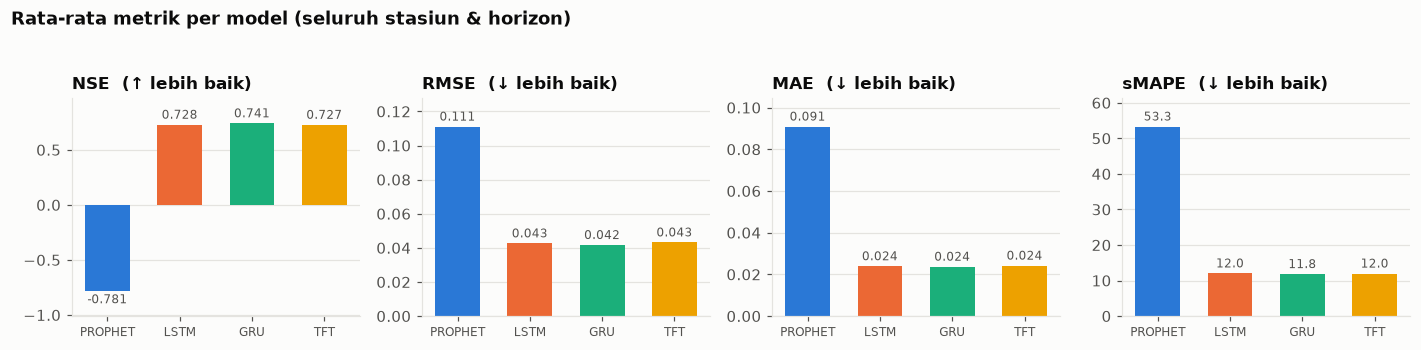

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, metric in zip(axes, METRICS):
    vals = summary[metric].reindex(MODELS)
    bars = ax.bar(MODELS, vals, color=[COLOR[m] for m in MODELS], width=0.62)
    ax.set_title(f"{metric}  ({'↑' if HIGHER_IS_BETTER[metric] else '↓'} lebih baik)")
    ax.set_xticks(range(len(MODELS)), [m.upper() for m in MODELS], fontsize=8)
    ax.grid(axis="x", visible=False)
    ax.bar_label(bars, fmt="%.3f" if metric != "sMAPE" else "%.1f", fontsize=8, color=INK_2, padding=2)
    ax.margins(y=0.15)
fig.suptitle("Rata-rata metrik per model (seluruh stasiun & horizon)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 2. Performa vs horizon

Seberapa cepat akurasi turun saat prediksi makin jauh ke depan. Tiap garis = rata-rata
seluruh stasiun. Prophet jauh di bawah, jadi dilanjutkan dengan zoom ke tiga model deep learning saja.

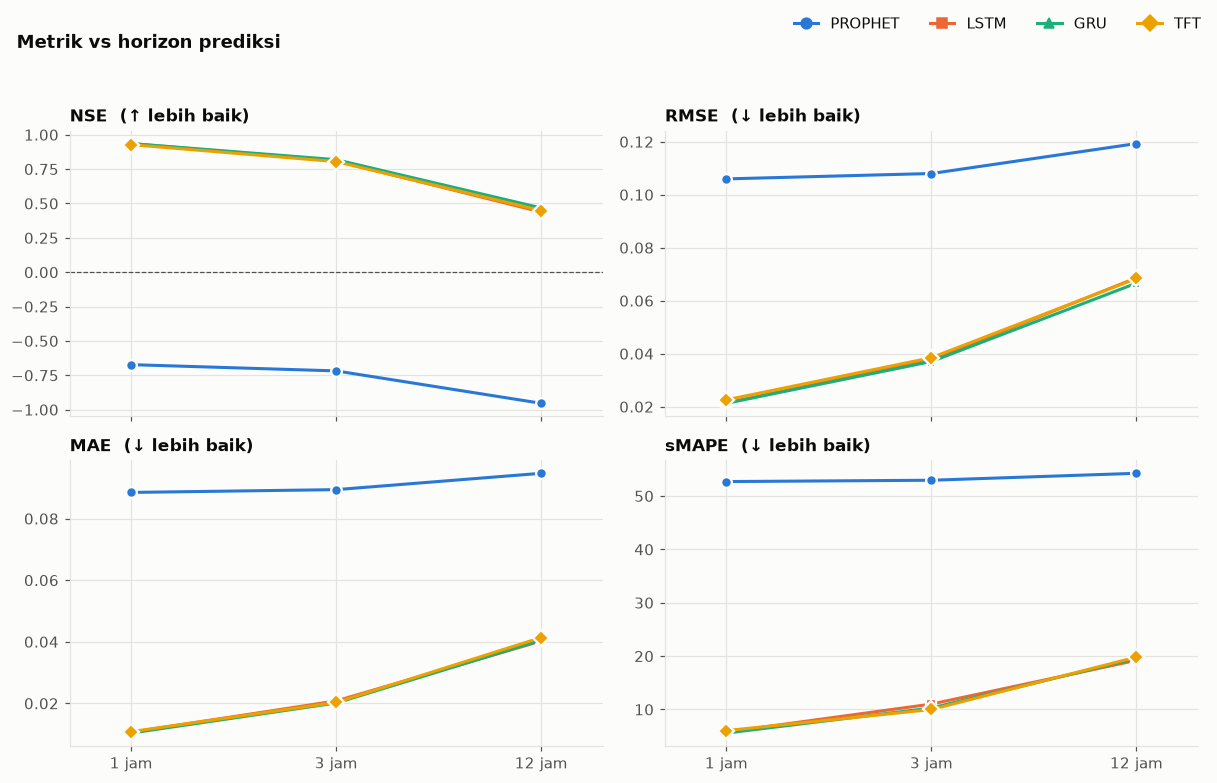

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, metric in zip(axes.flat, METRICS):
    for m in MODELS:
        g = df[df["model"] == m].groupby("horizon")[metric].mean()
        ax.plot(range(len(HORIZONS)), g.loc[HORIZONS], color=COLOR[m], marker=MARKER[m], lw=2, ms=7, mec=SURFACE, mew=1.5)
    ax.set_title(f"{metric}  ({'↑' if HIGHER_IS_BETTER[metric] else '↓'} lebih baik)")
    ax.set_xticks(range(len(HORIZONS)), [f"{h} jam" for h in HORIZONS])
    ax.set_xlim(-0.3, len(HORIZONS) - 0.7)
    if metric == "NSE":
        ax.axhline(0, color=INK_2, lw=0.8, ls="--")
model_legend(fig)
fig.suptitle("Metrik vs horizon prediksi", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

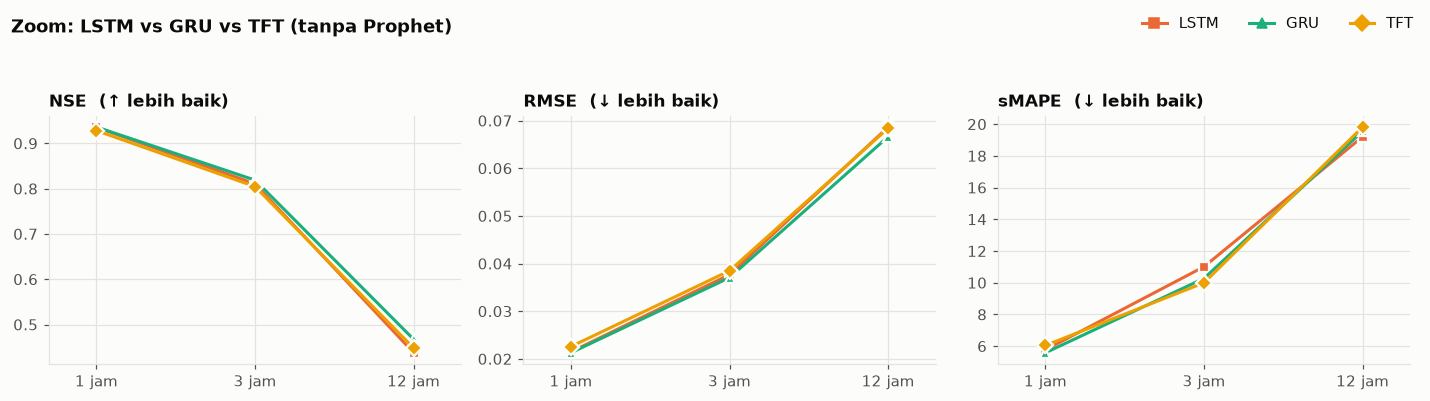

In [6]:
DL_MODELS = [m for m in MODELS if m != "prophet"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ["NSE", "RMSE", "sMAPE"]):
    for m in DL_MODELS:
        g = df[df["model"] == m].groupby("horizon")[metric].mean()
        ax.plot(range(len(HORIZONS)), g.loc[HORIZONS], color=COLOR[m], marker=MARKER[m], lw=2, ms=7, mec=SURFACE, mew=1.5)
    ax.set_title(f"{metric}  ({'↑' if HIGHER_IS_BETTER[metric] else '↓'} lebih baik)")
    ax.set_xticks(range(len(HORIZONS)), [f"{h} jam" for h in HORIZONS])
    ax.set_xlim(-0.3, len(HORIZONS) - 0.7)
fig.legend(handles=[plt.Line2D([], [], color=COLOR[m], marker=MARKER[m], lw=2, ms=7, label=m.upper()) for m in DL_MODELS],
           loc="upper right", ncol=3, bbox_to_anchor=(1, 1.02), handlelength=1.6)
fig.suptitle("Zoom: LSTM vs GRU vs TFT (tanpa Prophet)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

## 3. NSE per stasiun

Heatmap `stasiun × model` untuk tiap horizon. Skala warna dipotong di 0 (NSE ≤ 0
semua berwarna paling terang) — angkanya tetap tertulis di sel.

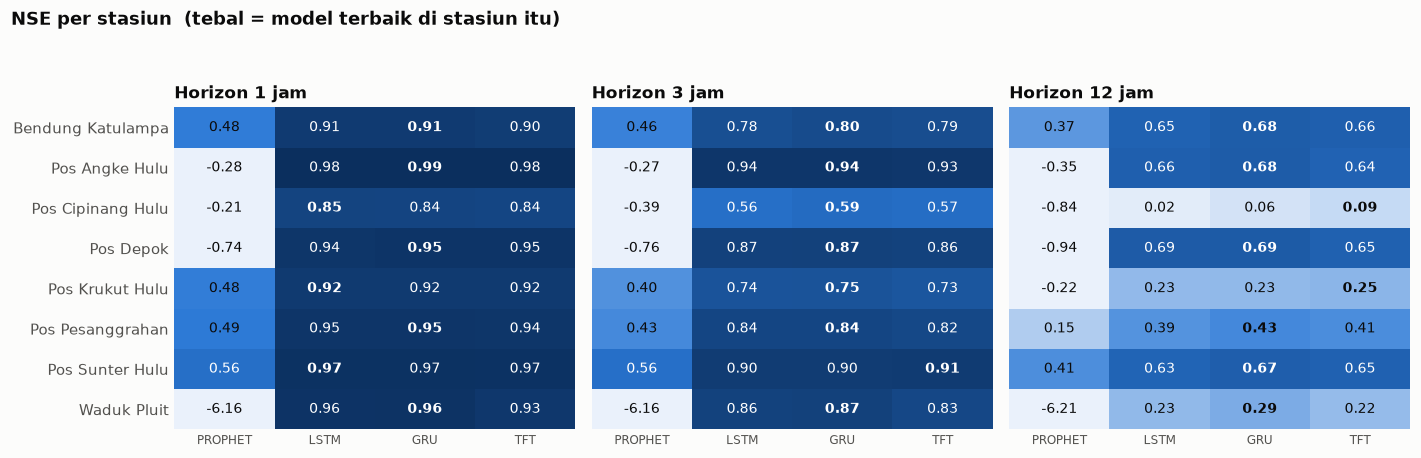

In [7]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(13, 4.2), sharey=True)
for ax, h in zip(axes, HORIZONS):
    piv = (df[df["horizon"] == h].pivot(index="station", columns="model", values="NSE")
             .loc[STATIONS, MODELS])
    ax.imshow(piv.values, cmap=NSE_RAMP, vmin=0, vmax=1, aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.55 else INK, fontweight="bold" if v == piv.values[i].max() else "normal")
    ax.set_xticks(range(len(MODELS)), [m.upper() for m in MODELS], fontsize=8)
    ax.set_yticks(range(len(STATIONS)), STATIONS)
    ax.set_title(f"Horizon {h} jam")
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
fig.suptitle("NSE per stasiun  (tebal = model terbaik di stasiun itu)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 4. Konsistensi antar stasiun

Kiri: sebaran NSE tiap model (satu titik = satu stasiun × horizon; garis hitam = rata-rata).
Kanan: berapa kali tiap model menjadi yang terbaik dari 24 kombinasi stasiun × horizon.

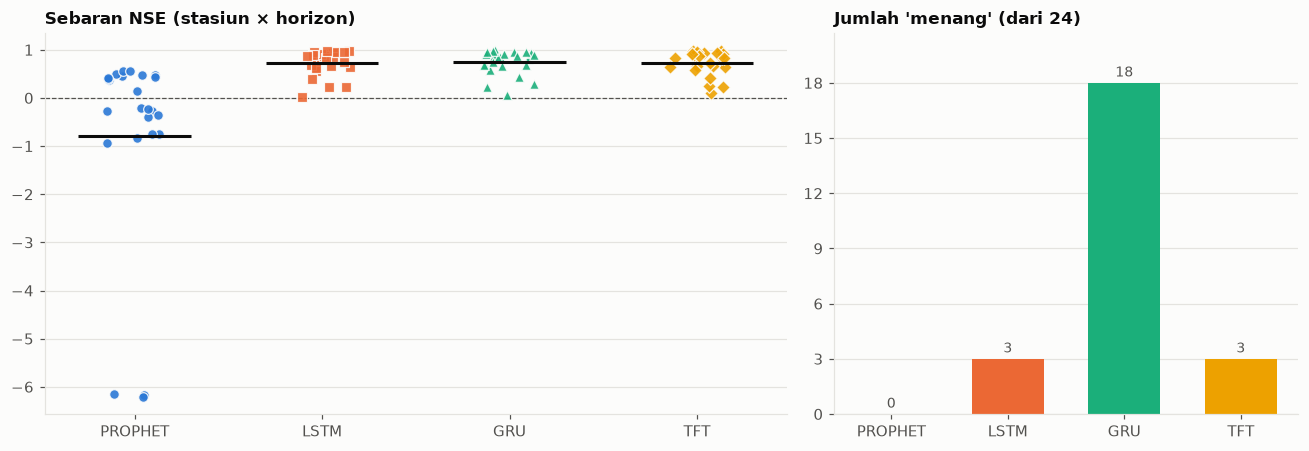

In [8]:
rng = np.random.default_rng(0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})

for i, m in enumerate(MODELS):
    v = df.loc[df["model"] == m, "NSE"].to_numpy()
    ax1.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=40, color=COLOR[m], marker=MARKER[m],
                edgecolor=SURFACE, linewidth=0.8, alpha=0.9, zorder=3)
    ax1.hlines(v.mean(), i - 0.3, i + 0.3, color=INK, lw=2, zorder=4)
ax1.axhline(0, color=INK_2, lw=0.8, ls="--")
ax1.set_xticks(range(len(MODELS)), [m.upper() for m in MODELS])
ax1.set_title("Sebaran NSE (stasiun × horizon)")
ax1.grid(axis="x", visible=False)

best = df.loc[df.groupby(["station", "horizon"])["NSE"].idxmax(), "model"].value_counts().reindex(MODELS, fill_value=0)
bars = ax2.bar(MODELS, best.values, color=[COLOR[m] for m in MODELS], width=0.62)
ax2.bar_label(bars, fontsize=9, color=INK_2, padding=2)
ax2.set_xticks(range(len(MODELS)), [m.upper() for m in MODELS])
ax2.set_title(f"Jumlah 'menang' (dari {len(STATIONS) * len(HORIZONS)})")
ax2.grid(axis="x", visible=False)
ax2.margins(y=0.15)
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

## 5. Detail per stasiun

NSE vs horizon untuk tiap stasiun — untuk melihat stasiun mana yang sulit
diprediksi oleh semua model, dan di mana kualitas jatuh paling cepat.

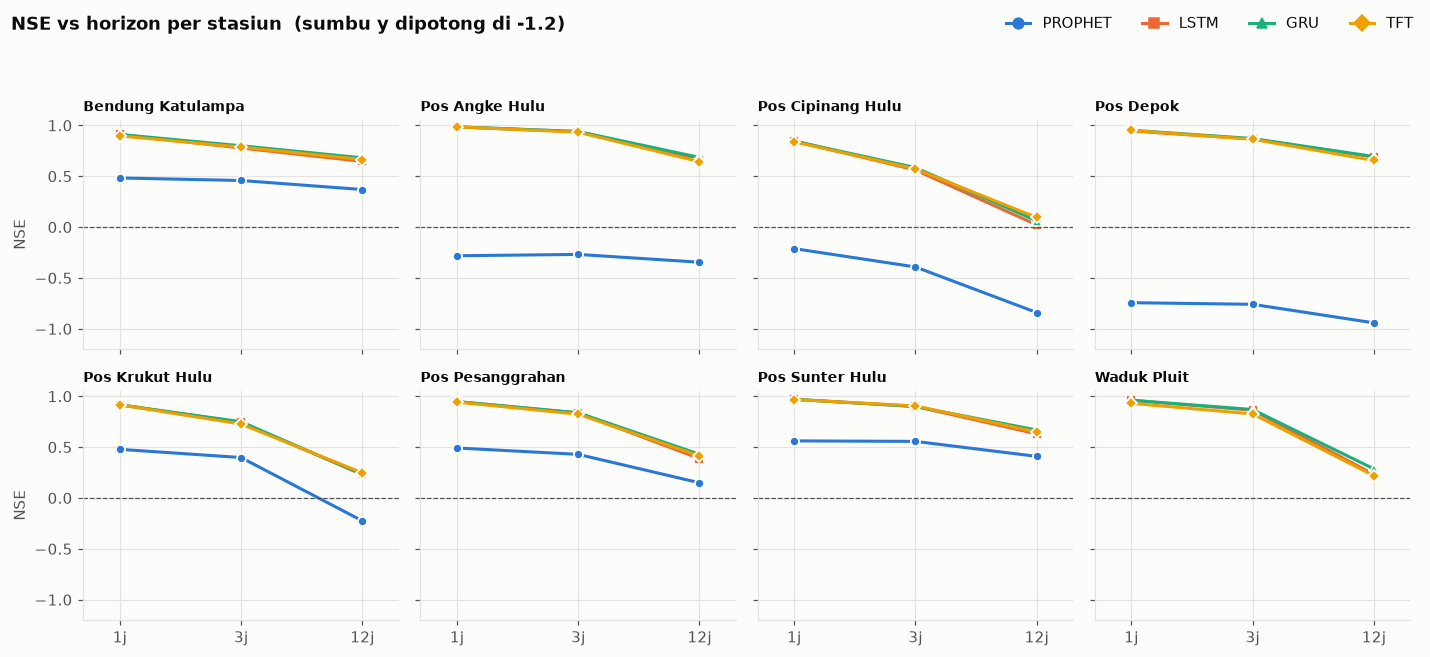

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, st in zip(axes.flat, STATIONS):
    sub = df[df["station"] == st]
    for m in MODELS:
        s = sub[sub["model"] == m].sort_values("horizon")
        ax.plot([HORIZONS.index(h) for h in s["horizon"]], s["NSE"], color=COLOR[m], marker=MARKER[m], lw=2, ms=6, mec=SURFACE, mew=1.2)
    ax.axhline(0, color=INK_2, lw=0.8, ls="--")
    ax.set_title(st, fontsize=9)
    ax.set_xticks(range(len(HORIZONS)), [f"{h}j" for h in HORIZONS])
    ax.set_xlim(-0.3, len(HORIZONS) - 0.7)
    ax.set_ylim(-1.2, 1.05)
for ax in axes[:, 0]: ax.set_ylabel("NSE")
model_legend(fig, y=1.0)
fig.suptitle("NSE vs horizon per stasiun  (sumbu y dipotong di -1.2)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 6. Tabel lengkap

Semua metrik per `model × stasiun × horizon`, untuk dilihat angka persisnya atau disalin ke tulisan.

In [10]:
full = df.set_index(["station", "horizon", "model"])[METRICS].sort_index()
full.style.format("{:.4f}").background_gradient(subset=["NSE"], cmap="Blues", vmin=0, vmax=1)

> **Catatan:** tabel sumber tidak punya kolom `split` (validation vs test), jadi laporan ini
> membaca angkanya apa adanya. Kalau di Looker kolom ini berasal dari `*_val_metrics_hourly`
> atau `*_metrics_hourly`, sebutkan di bab hasil skripsi.